# Heart Disease Prediction using Machine Learning

**Course:** Fundamentals of Machine Learning – Programming Assignment
**Group members:** *MS26923406*, *MS26923338*
**Dataset:** UCI Heart Disease Data
**Dataset source:** https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data

**Problem:** Predict whether a patient has heart disease from clinical measurements (binary classification, supervised learning).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

# imports for the baseline, nested CV and permutation importance
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_style("whitegrid")

## Load the dataset
The dataset is the Kaggle *Heart Disease Data* file (`heart_disease_uci.csv`). 

In [2]:
COLS = ['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

def load_data():
    try:
        df = pd.read_csv("heart_disease_uci.csv")

        # Assign column names only if needed
        if len(df.columns) == len(COLS):
            df.columns = COLS
        else:
            raise ValueError("Unexpected number of columns")

        print("Dataset loaded successfully")
        return df

    except Exception as e:
        print(f"Cannot load the dataset: {e}")
        raise

df = load_data()

# Convert only numeric columns
num_cols = ['id', 'age', 'trestbps', 'chol', 'thalch', 'oldpeak']

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Dataset shape:", df.shape)
display(df.head())
print(df.dtypes)


Dataset loaded successfully
Dataset shape: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


id            int64
age           int64
sex          object
dataset      object
cp           object
trestbps    float64
chol        float64
fbs          object
restecg      object
thalch      float64
exang        object
oldpeak     float64
slope        object
ca          float64
thal         object
num           int64
dtype: object


## Prepare the data

The original target (`num` in the source dataset) uses values from 0 to 4. We convert it to a binary target called `target`: **0 = no heart disease** and **1 = heart disease present**.

**Columns that are NOT used as features:**
- `num` is the original label. Using it as an input would leak the answer to the model.
- `id` is only a row number (and the rows are sorted by hospital), so it carries no clinical information.
- `dataset` is the hospital the record came from. Its disease rate differs a lot between hospitals (see the table in the EDA section), so a model could learn "which hospital" instead of real clinical signals.

**Data-quality fixes:** `trestbps` (resting blood pressure) and `chol` (cholesterol) contain the value `0`, which is physiologically impossible and means "not recorded", so these zeros are converted to missing values. The columns `slope`, `ca` and `thal` are missing for many patients; missing values in categorical columns are kept as their own category (`"missing"`) instead of being filled with a guessed value.

In [3]:
TARGET = "target"

# Binary target from the original label (0 = no disease, 1-4 = disease)
df["num"] = pd.to_numeric(df["num"], errors="coerce")
df = df.dropna(subset=["num"]).copy()
df[TARGET] = (df["num"] > 0).astype(int)

# Impossible zero values -> missing
zero_cols = ["trestbps", "chol"]
print("Zero values found (treated as missing):")
print((df[zero_cols] == 0).sum())
df[zero_cols] = df[zero_cols].replace(0, np.nan)

# True/False and the 0-3 vessel count are categories, so store them as text
for col in ["fbs", "exang"]:
    df[col] = df[col].map({True: "True", False: "False"})
df["ca"] = df["ca"].map(lambda v: str(int(v)) if pd.notna(v) else np.nan)

# Feature columns (id, dataset and num are deliberately excluded)
num_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"]
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
feature_cols = num_cols + cat_cols

print("\nDataset rows and columns:", df.shape)

print("\nMissing values by column:")
missing_values = df[feature_cols].isna().sum()
print(
    missing_values[missing_values > 0]
    if missing_values.any()
    else "No missing values found."
)

print("\nClass counts:")
print(
    df[TARGET].value_counts()
    .sort_index()
    .rename(index={0: "No disease", 1: "Disease"})
)

print("\nClass proportions:")
print(
    df[TARGET].value_counts(normalize=True)
    .sort_index()
    .round(3)
    .rename(index={0: "No disease", 1: "Disease"})
)

print("\nDescriptive statistics (numeric features):")
display(df[num_cols].describe().T.round(2))

Zero values found (treated as missing):
trestbps      1
chol        172
dtype: int64

Dataset rows and columns: (920, 17)

Missing values by column:
trestbps     60
chol        202
thalch       55
oldpeak      62
fbs          90
restecg       2
exang        55
slope       309
ca          611
thal        486
dtype: int64

Class counts:
target
No disease    411
Disease       509
Name: count, dtype: int64

Class proportions:
target
No disease    0.447
Disease       0.553
Name: proportion, dtype: float64

Descriptive statistics (numeric features):


,count,mean,std,min,25%,50%,75%,max
age,920.0,53.51,9.42,28.0,47.0,54.0,60.00,77.0
trestbps,860.0,132.29,18.54,80.0,120.0,130.0,140.00,200.0
chol,718.0,246.83,58.53,85.0,210.0,239.5,276.75,603.0
thalch,865.0,137.55,25.93,60.0,120.0,140.0,157.00,202.0
oldpeak,858.0,0.88,1.09,-2.6,0.0,0.5,1.50,6.2


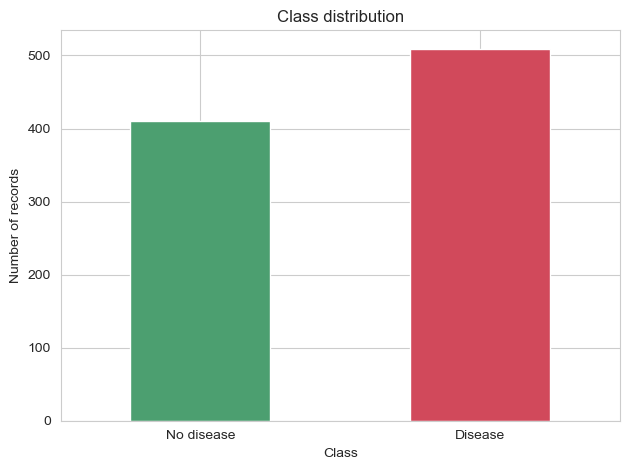

In [4]:
df[TARGET].value_counts().sort_index().plot(
    kind="bar", color=["#4C9F70", "#D1495B"]
)

plt.xticks([0, 1], ["No disease", "Disease"], rotation=0)
plt.title("Class distribution")
plt.ylabel("Number of records")
plt.xlabel("Class")

plt.tight_layout()
plt.show()

### Exploratory data analysis

The table shows how the disease rate differs between hospitals (the reason `dataset` is not used as a feature). The plots compare the numeric features between the two classes (boxplots also show outliers), show how the categorical features relate to the target (including how many values are missing), and give the correlation between the numeric features and the target.

Patients and disease rate by data source:


,patients,disease_rate
dataset,,
Cleveland,304,0.457
Hungary,293,0.362
Switzerland,123,0.935
VA Long Beach,200,0.745


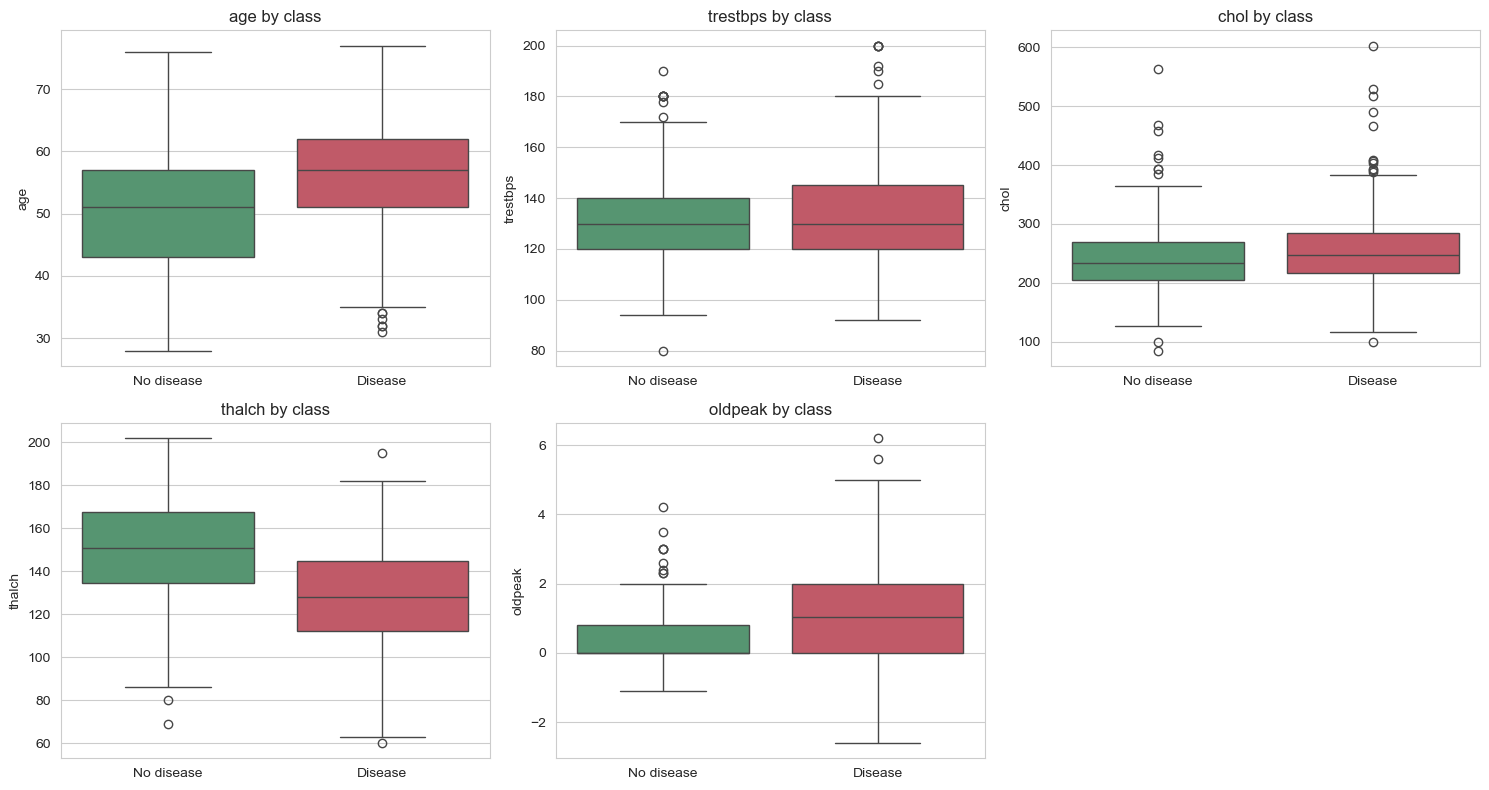

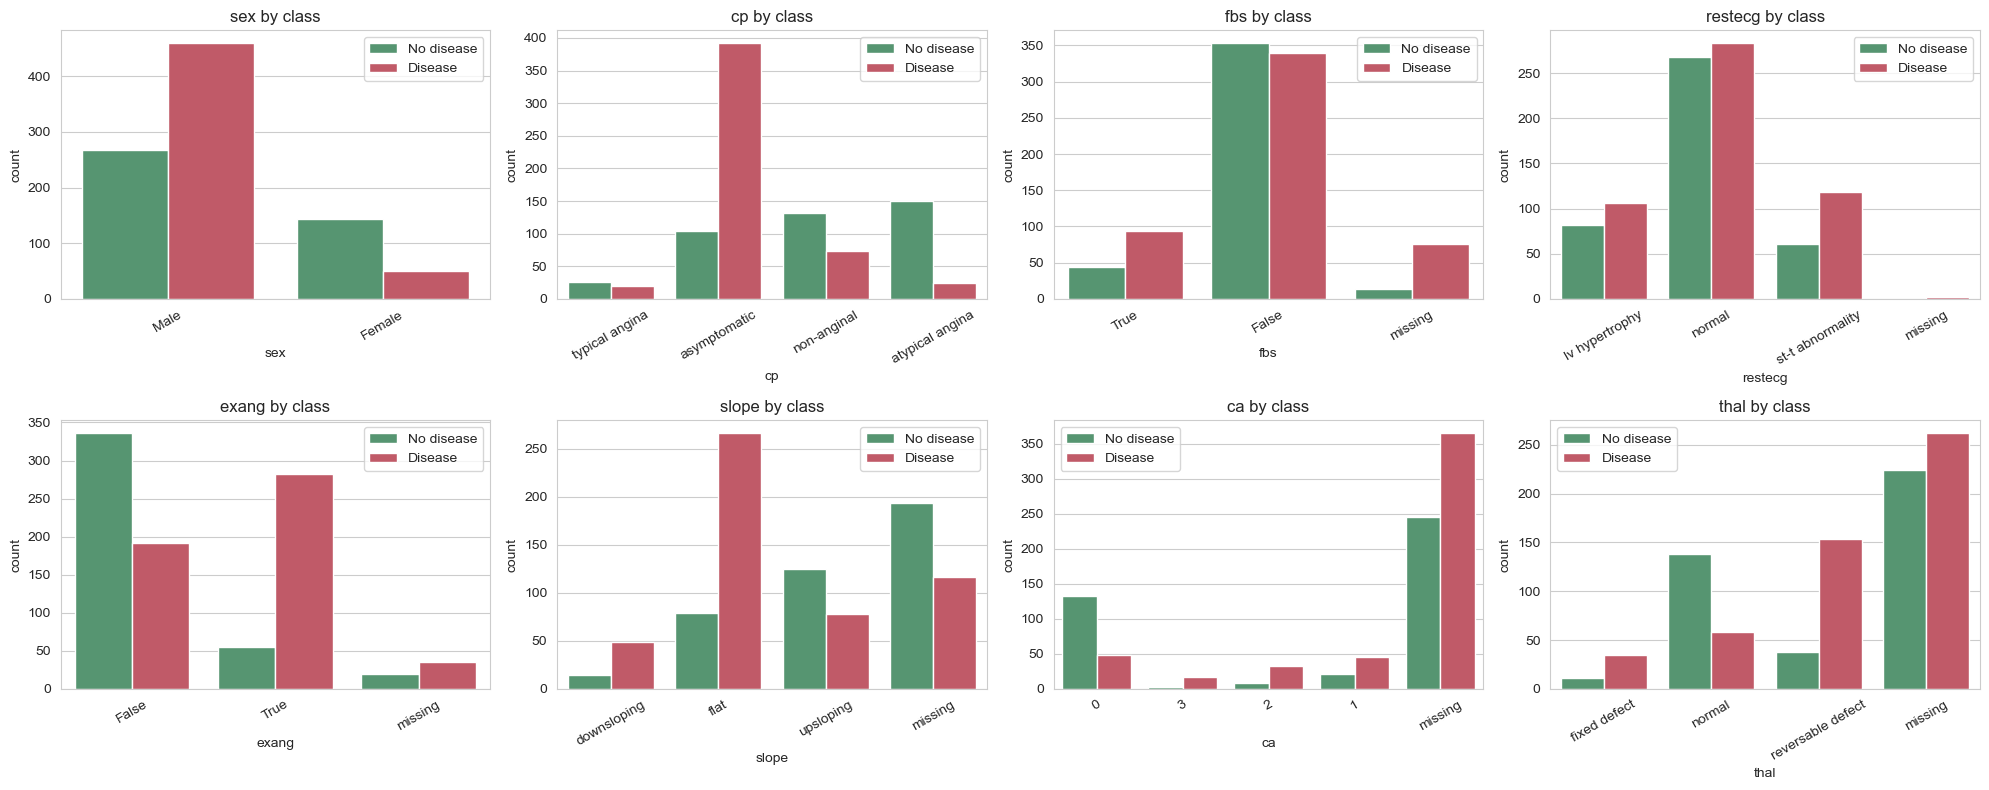

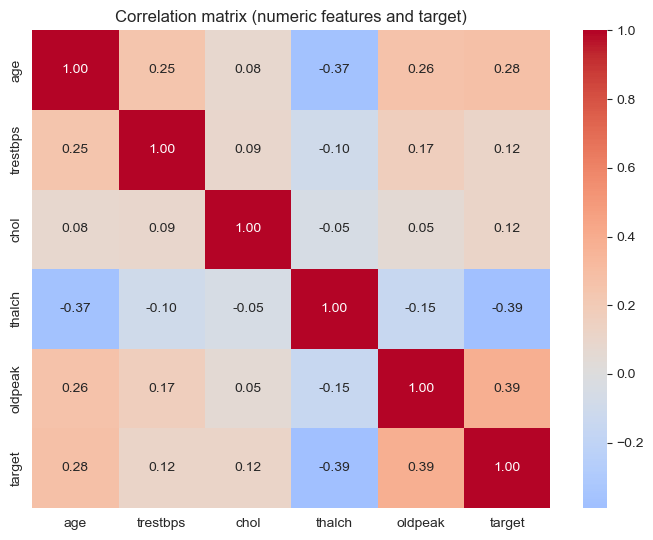

In [5]:
palette = ["#4C9F70", "#D1495B"]

# 0) Disease rate by source hospital
print("Patients and disease rate by data source:")
display(df.groupby("dataset")[TARGET].agg(patients="count", disease_rate="mean").round(3))

# 1) Numeric features by class
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x=TARGET, y=col, palette=palette, ax=ax)
    ax.set_xticklabels(["No disease", "Disease"])
    ax.set_xlabel("")
    ax.set_title(f"{col} by class")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

# 2) Categorical features by class (missing values shown as their own bar)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    plot_df = df.assign(**{col: df[col].fillna("missing")})
    sns.countplot(data=plot_df, x=col, hue=TARGET, palette=palette, ax=ax)
    ax.set_title(f"{col} by class")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="", labels=["No disease", "Disease"])
plt.tight_layout()
plt.show()

# 3) Correlation between numeric features and the target
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[num_cols + [TARGET]].corr().round(2), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features and target)")
plt.tight_layout()
plt.show()

### Train/test split and preprocessing pipeline

- Only the clinical feature columns are used: `id`, `dataset` and the original label `num` are excluded.
- We keep 20% of the data for final testing and use stratification to preserve the class proportions.
- Numeric columns are imputed with the median and scaled.
- Categorical columns keep missing values as their own `"missing"` category and are one-hot encoded.

In [6]:
# Separate input feature columns and target label
X = df[feature_cols]
y = df[TARGET]

# Split dataset into stratified 80% train and 20% test sets to preserve class ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Define preprocessing: median impute & scale numeric; constant impute & one-hot encode categorical
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Training records: 736
Testing records: 184


## Algorithm 1: Random Forest

In [7]:
# Build an end-to-end pipeline with data preprocessing and Random Forest
rf_pipe = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"))
])

# Define hyperparameter grid for tree count, depth, leaf samples, and feature subsets
rf_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [None, 4, 8],
    "clf__min_samples_leaf": [1, 3, 5],
    "clf__max_features": ["sqrt", "log2"],
}

# Run grid search cross-validation optimizing for F1-score across all CPU cores
rf_search = GridSearchCV(
    rf_pipe, rf_grid, cv=cv, scoring="f1", n_jobs=-1, refit=True
)
rf_search.fit(X_train, y_train)
# Store the best-performing pipeline refitted on all training data
rf_best = rf_search.best_estimator_

print("Best Random Forest parameters:", rf_search.best_params_)
print("Best training CV F1-score:", round(rf_search.best_score_, 4))

Best Random Forest parameters: {'clf__max_depth': 8, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}
Best training CV F1-score: 0.8503


## Algorithm 2: Support Vector Machine

In [8]:
# Create an end-to-end pipeline with preprocessing and SVM (probability=True for ROC-AUC)
svm_pipe = Pipeline([
    ("prep", preprocess), 
    ("clf", SVC(probability=True, random_state=RANDOM_STATE))
])

# Define hyperparameter grid for tuning C, gamma, and kernel type
svm_grid = {
    "clf__C": [0.1, 1, 10, 100],
    "clf__gamma": ["scale", 0.01, 0.1],
    "clf__kernel": ["rbf", "linear"],
}

# Run 5-fold grid search cross-validation optimizing for F1-score
svm_search = GridSearchCV(svm_pipe, svm_grid, cv=cv, scoring="f1", n_jobs=-1)
svm_search.fit(X_train, y_train)

# Display the best hyperparameters and corresponding CV score
print("Best params:", svm_search.best_params_)
print("Best CV F1 :", round(svm_search.best_score_, 4))

# Save the best-performing model refitted on all training data
svm_best = svm_search.best_estimator_

Best params: {'clf__C': 1, 'clf__gamma': 0.1, 'clf__kernel': 'rbf'}
Best CV F1 : 0.8591


## Final evaluation on the held-out test set

The following metrics are calculated from predictions on the test set, which was not used to tune the models. Because this is a medical classification example, recall is important to discuss alongside the other metrics.

In [9]:
# Compute key test classification metrics for a given model
def evaluate_model(name, model):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }

# Evaluate both tuned models and compile metrics into a comparison table
models = [("Random Forest", rf_best), ("SVM", svm_best)]
results = pd.DataFrame([evaluate_model(name, model) for name, model in models]).set_index("Model")

# Display rounded performance results
display(results.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.8478,0.8491,0.8824,0.8654,0.9264
SVM,0.8424,0.8174,0.9216,0.8664,0.9152


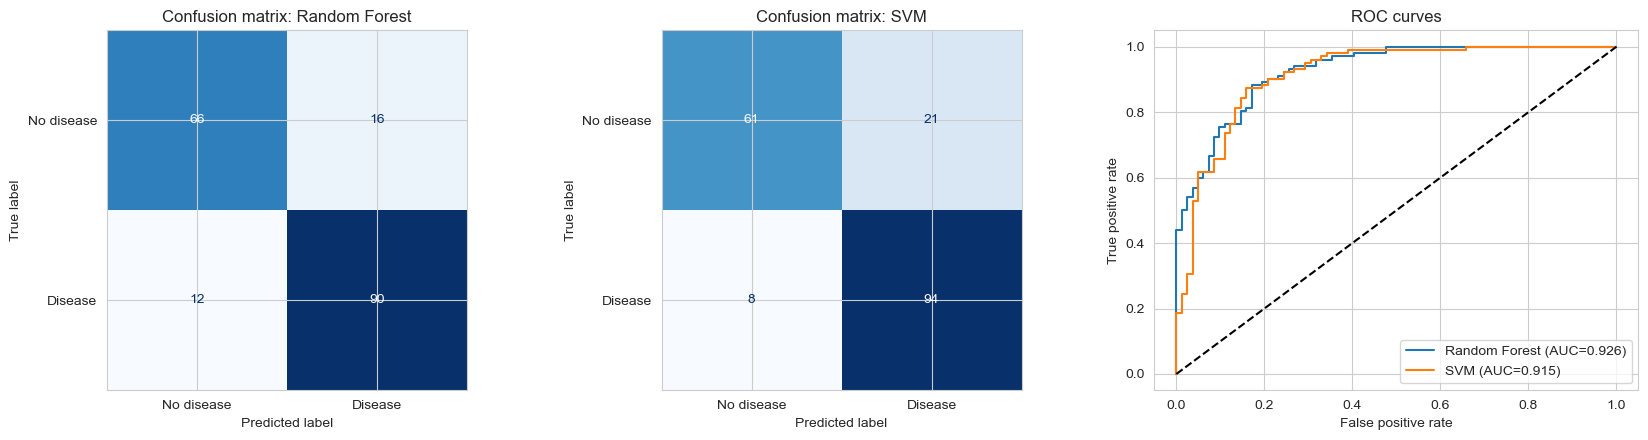

--- Random Forest ---
              precision    recall  f1-score   support

  No disease       0.85      0.80      0.82        82
     Disease       0.85      0.88      0.87       102

    accuracy                           0.85       184
   macro avg       0.85      0.84      0.85       184
weighted avg       0.85      0.85      0.85       184

--- SVM ---
              precision    recall  f1-score   support

  No disease       0.88      0.74      0.81        82
     Disease       0.82      0.92      0.87       102

    accuracy                           0.84       184
   macro avg       0.85      0.83      0.84       184
weighted avg       0.85      0.84      0.84       184



In [10]:
# Create a 1x3 subplot grid for visualizations
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Plot normalized/standard confusion matrices for Random Forest and SVM on test data
for ax, (name, m) in zip(axes[:2], [("Random Forest", rf_best), ("SVM", svm_best)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
                           display_labels=["No disease", "Disease"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix: {name}")

# Compute and plot ROC curves with their corresponding AUC scores
for name, m in [("Random Forest", rf_best), ("SVM", svm_best)]:
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    axes[2].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, m.predict_proba(X_test)[:,1]):.3f})")

# Add chance baseline diagonal, axis labels, title, and legend to the ROC plot
axes[2].plot([0, 1], [0, 1], "k--"); axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
axes[2].set_title("ROC curves"); axes[2].legend()
plt.tight_layout(); plt.show()

# Print detailed precision, recall, and F1 metrics for each class per model
for name, m in [("Random Forest", rf_best), ("SVM", svm_best)]:
    print(f"--- {name} ---")
    print(classification_report(y_test, m.predict(X_test), target_names=["No disease", "Disease"]))

### How reliable is the test-set accuracy?

With a small test set, one prediction changes accuracy noticeably. The 95% bootstrap confidence interval below shows how much the test accuracy could vary. If the two intervals overlap heavily, the test set alone cannot decide which model is better.

In [11]:
# Initialize a reproducible random number generator
boot_rng = np.random.default_rng(RANDOM_STATE)

# Estimate 95% bootstrap confidence intervals for test accuracy per model
for name, m in models:
    # Identify correct predictions (1 for correct, 0 for incorrect)
    correct = (m.predict(X_test) == y_test.values).astype(int)

    # Resample accuracy 5,000 times with replacement
    boots = [boot_rng.choice(correct, size=len(correct), replace=True).mean() for _ in range(5000)]

    # Compute the 2.5th and 97.5th percentiles for the 95% CI
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f"{name}: test accuracy = {correct.mean():.3f}  "
          f"(95% bootstrap CI: {lo:.3f} to {hi:.3f}, n = {len(correct)})")

Random Forest: test accuracy = 0.848  (95% bootstrap CI: 0.793 to 0.897, n = 184)
SVM: test accuracy = 0.842  (95% bootstrap CI: 0.788 to 0.891, n = 184)


### Cross-validation results used during tuning

The table below reports the mean and standard deviation of the **best F1-score across the five training folds** for each grid search. These scores helped select the hyperparameters; they are not a separate unbiased test of the final model. Use the held-out test-set table above for the final model comparison.

In [12]:
# Initialize a list to store cross-validation summary records
cv_rows = []

# Extract the optimal CV mean F1-score and its standard deviation for each model
for name, search in [("Random Forest", rf_search), ("SVM", svm_search)]:
    best_index = search.best_index_
    cv_rows.append({
        "Model": name,
        "Best mean CV F1-score": search.cv_results_["mean_test_score"][best_index],
        "CV F1 standard deviation": search.cv_results_["std_test_score"][best_index],
    })

# Convert summary rows to a DataFrame indexed by model name
cv_summary = pd.DataFrame(cv_rows).set_index("Model")

# Display the formatted cross-validation results rounded to 4 decimal places
display(cv_summary.round(4))

,Best mean CV F1-score,CV F1 standard deviation
Model,,
Random Forest,0.8503,0.0197
SVM,0.8591,0.0215


## Feature importance

Random Forest provides an estimate of feature importance. These scores describe how much the fitted forest used each transformed feature; they do not prove that a feature causes heart disease. One-hot encoding means a single original categorical variable may appear as several features.

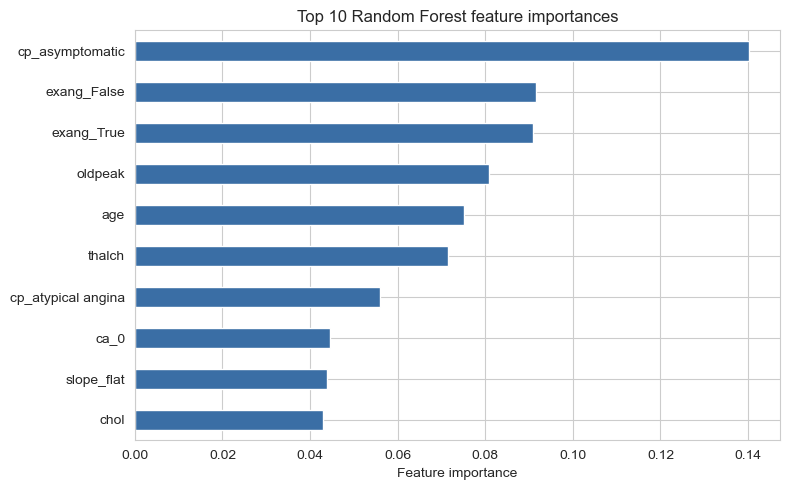

In [13]:
# Extract clean feature names by stripping column transformer prefixes
feature_names = [n.split("__", 1)[1] for n in rf_best.named_steps["prep"].get_feature_names_out()]

# Map Gini importances to feature names and select the top 10 most influential features
importances = pd.Series(
    rf_best.named_steps["clf"].feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

# Plot top 10 feature importances as a horizontal bar chart in ascending order
importances.sort_values().plot(
    kind="barh", figsize=(8, 5), color="#3A6EA5"
)

# Set chart labels, title, and display the plot
plt.xlabel("Feature importance")
plt.title("Top 10 Random Forest feature importances")
plt.tight_layout()
plt.show()

### Permutation importance (both models)

Permutation importance shuffles one *original* feature at a time on the test set and measures how much the F1-score drops. Unlike the built-in Random Forest importance, it works for any model (including the SVM) and is not split across one-hot columns. Bars show the mean drop, and the error bars show the standard deviation over 30 shuffles.

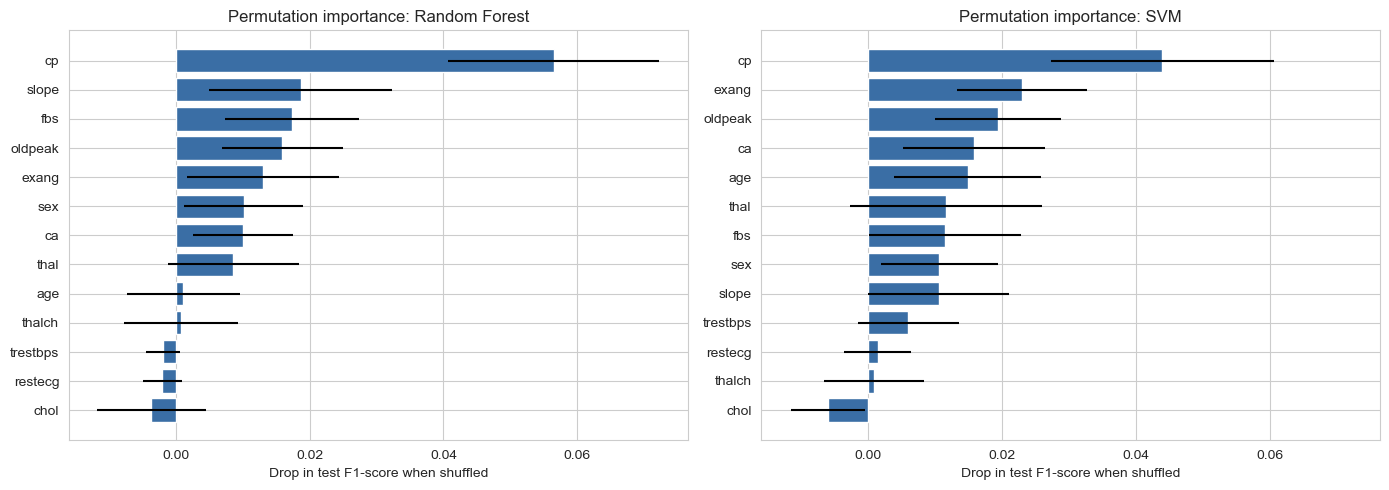

In [14]:
# Create a side-by-side subplot comparison sharing the horizontal axis
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

# Calculate and plot permutation importance on the test set for each model
for ax, (name, m) in zip(axes, models):

    # Shuffle each feature 30 times to observe the drop in test F1-score
    r = permutation_importance(m, X_test, y_test, scoring="f1", n_repeats=30,
                               random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values()
    err = pd.Series(r.importances_std, index=X_test.columns).reindex(imp.index)
    ax.barh(imp.index, imp.values, xerr=err.values, color="#3A6EA5")
    ax.set_title(f"Permutation importance: {name}")
    ax.set_xlabel("Drop in test F1-score when shuffled")
plt.tight_layout()
plt.show()